# Reproducing *Signatures of Compact Object Mergers Inside Stars in AGN Disks*

**Cantiello et al. (2026)**

This notebook is the single place to reproduce the paper. Run it from top to bottom
(*Kernel → Restart & Run All*) and it will:

1. build the stellar model used throughout the paper,
2. remake **all nine figures** and save them in `figures/` under the file names the manuscript uses, and
3. recompute **every major number quoted in the text** and compare it with the value printed in the paper.

All the physics lives in the small `agn_cee` Python package in this repository; the notebook explains
each step in plain language and calls the package. Nothing here needs a supercomputer: the whole notebook
runs in under a minute on a laptop.

### How to run it

From the repository root:

```bash
pip install -r requirements.txt
jupyter lab reproduce_paper.ipynb
```

### How to read the number checks

Every section ends with a short list of lines like

```
OK  spiral-in time of a 10 Msun BH        code = 0.108 yr     paper ~ 0.1 yr     [Sec. 3.3]
```

The paper rounds most values (often to one significant figure, sometimes to an order of magnitude),
so each check passes if the code and paper agree **within a stated factor** (shown as `tol`). A line
marked `XX` would mean the code and the paper disagree. The last cell lists every check in one table.

### The story in one paragraph

Gas disks around supermassive black holes (active galactic nuclei, AGN) can feed stars so fast that fresh
hydrogen reaches the stellar core as quickly as it burns. These stars stop evolving and grow to hundreds of
solar masses; we call them **immortal stars**. Stellar-mass black holes (BHs) also live in the disk. The paper
asks what happens when a BH, or a pair of BHs, falls into an immortal star. A single BH sinks to the
center in about a month. A pair of BHs at the center is driven together by the dense gas in about an hour,
far faster than by gravitational-wave emission alone, and then merges. The merger is a normal-looking source for
LIGO–Virgo–KAGRA (LVK), but the dense gas leaves a strong imprint at deci-Hz frequencies, a band that future
detectors such as DECIGO would cover. The energy released while the pair spirals together is comparable to the
energy holding the star together, so each star likely hosts only one or two such mergers.

### Words you will meet

| Term | Meaning |
|---|---|
| **Immortal star** | A massive star in an AGN disk whose core is constantly refuelled by accreted gas, so it stays on the main sequence indefinitely. Our model star has 773 $M_\odot$ and a radius of 12.5 $R_\odot$. |
| **Compact object (CO), BH, BBH** | A neutron star or black hole; BH = black hole; BBH = binary black hole (two BHs orbiting each other). |
| **Accretion stream** | The gas falling onto the star from the surrounding disk, from the **Bondi radius** (where the star's gravity starts to dominate the disk gas) down to the stellar surface. |
| **Dynamical friction (DF)** | A drag force without contact: a moving mass pulls the gas behind it into a dense wake, and the wake's gravity pulls the mass back. It is the main way a BH loses orbital energy inside the star. |
| **Bondi–Hoyle–Lyttleton (BHL) accretion** | The rate at which a moving mass captures gas from its surroundings. The captured gas also carries momentum, which acts as a second, smaller drag (*accretion drag*). |
| **Mach number** | Speed divided by the local sound speed; above 1 the motion is *supersonic*. |
| **Hardening** | A binary's orbit shrinking (the two BHs getting closer). |
| **Gravitational waves (GW)** | Ripples in spacetime emitted by orbiting masses. They also carry energy away, so they harden the binary, but only slowly unless the BHs are very close. |
| **Gas–GW crossover** | The separation at which GW emission takes over from gas drag as the main driver of hardening. |
| **ISCO** | Innermost stable circular orbit; we stop the inspiral there (the merger happens right after). |
| **LISA / DECIGO / LVK** | GW detectors sensitive at milli-Hz (LISA, planned space mission), deci-Hz (DECIGO, proposed), and 10–1000 Hz (LIGO–Virgo–KAGRA, operating). |
| **Dephasing** | How many wave cycles a binary in gas skips relative to the same binary in empty space (vacuum). |
| **Characteristic strain** $h_c$ | A way to plot a GW signal's strength against a detector's noise curve: if the signal lies above the curve, it is detectable. |
| **SNR** | Signal-to-noise ratio; roughly, a source with SNR above about 8 counts as detected. |
| **Binding energy** | The energy needed to unbind the star. We quote the gravitational binding energy $\lvert E_{\rm grav}\rvert$ and the *net* binding energy $E_\ast=\lvert E_{\rm grav}\rvert-E_{\rm int}$, which subtracts the star's own internal (thermal plus radiation) energy. $E_\ast$ is the relevant threshold for unbinding the star. |
| **Eddington luminosity / rate** | The luminosity at which radiation pressure balances gravity, and the corresponding accretion rate. |

## 0. Setup

We import the package, define a small helper that compares code values with the paper, and build the stellar
model once. The model glues together two pieces:

* the **star itself**, read from a stellar-evolution model computed with the MESA code
  (`data/14547_cs10_RHO_3d-17_profile20.data`), and
* the **accretion stream** outside it, described by simple power laws (density $\propto r^{-3/2}$) that match
  the AGN disk at the Bondi radius.

Units are CGS throughout (grams, centimetres, seconds). Run this notebook from the repository root so the
data files are found.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from agn_cee import (constants as c, structure, physics, inspiral, bbh,
                     observability, rates, figures, review, plotstyle)
plotstyle.apply()   # re-apply the paper style after Jupyter's inline backend resets it,
                    # so the saved PDFs match the manuscript's figures exactly

Msun, Rsun, G = c.MSUN, c.RSUN, c.G
YR, HR, MYR = c.YR, 3600.0, 1e6 * c.YR
MBH = 10 * Msun                           # fiducial black-hole mass used in the paper

# ---- figures are written to figures/ with the manuscript's file names ----
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)
def save(fig, name, paper_label):
    path = os.path.join(FIGDIR, name)
    fig.savefig(path, metadata={"CreationDate": None})   # no timestamp -> reruns are byte-stable
    print(f"{paper_label} -> {path}")

# ---- compare a value computed here with the value printed in the paper ----
CHECKS = []
def check(what, value, paper, unit="", where="", tol=1.5):
    '''Pass if code and paper agree within a factor `tol` (the paper rounds its numbers).'''
    value, paper = float(value), float(paper)
    ok = bool(np.isfinite(value) and value * paper > 0
              and abs(np.log10(value / paper)) <= np.log10(tol))
    CHECKS.append(dict(what=what, value=value, paper=paper, unit=unit, where=where, tol=tol, ok=ok))
    print(f"{'OK' if ok else 'XX'}  {what:<52s} code = {value:<9.3g} {unit:<9s} "
          f"paper ~ {paper:<8.3g} (tol x{tol:g})  [{where}]")

# ---- the fiducial immortal star (Fig. 1) ----
model = structure.build_model(structure.DEFAULT_PROFILE)
mesa = structure.load_mesa_profile(structure.DEFAULT_PROFILE)     # raw MESA columns
print(f"Immortal star: M = {model.m_star/Msun:.0f} Msun, R = {model.r_shock/Rsun:.2f} Rsun, "
      f"central density = {model.rho_c:.1f} g/cm^3")

Immortal star: M = 773 Msun, R = 12.54 Rsun, central density = 15.9 g/cm^3


## 1. The immortal star (paper Sec. 2, Fig. 1)

**What the figure shows.** Density, sound speed, enclosed mass and inflow speed as a function of radius. Left
of the dotted line is the star (from MESA); right of it is the accretion stream that feeds the star from the
AGN disk out to the Bondi radius ($\approx 3\times10^6\,R_\odot\approx0.07$ pc).

**Why it matters.** Every later calculation reads the local gas density $\rho(r)$, sound speed $c_s(r)$ and
enclosed mass $M_{\rm en}(r)$ from this model. As in the paper, the fiducial sound speed counts only the gas
pressure, $c_s=\sqrt{(5/3)P_{\rm gas}/\rho}$; the star is so massive that radiation supplies most of its
pressure (only $\beta = P_{\rm gas}/P_{\rm tot}\approx0.2$ in the core), and Section 4 of this notebook shows how the results
change if radiation pressure is included.

**Binding energy.** Because radiation pressure does most of the work of holding the star up, the star's internal
energy almost cancels its gravitational binding energy: the *net* binding energy $E_\ast$ is only about 12% of
$\lvert E_{\rm grav}\rvert$. This is the number that matters later when we ask whether a merger can blow the
star apart.

Fig. 1 -> figures/fig1_structure.pdf


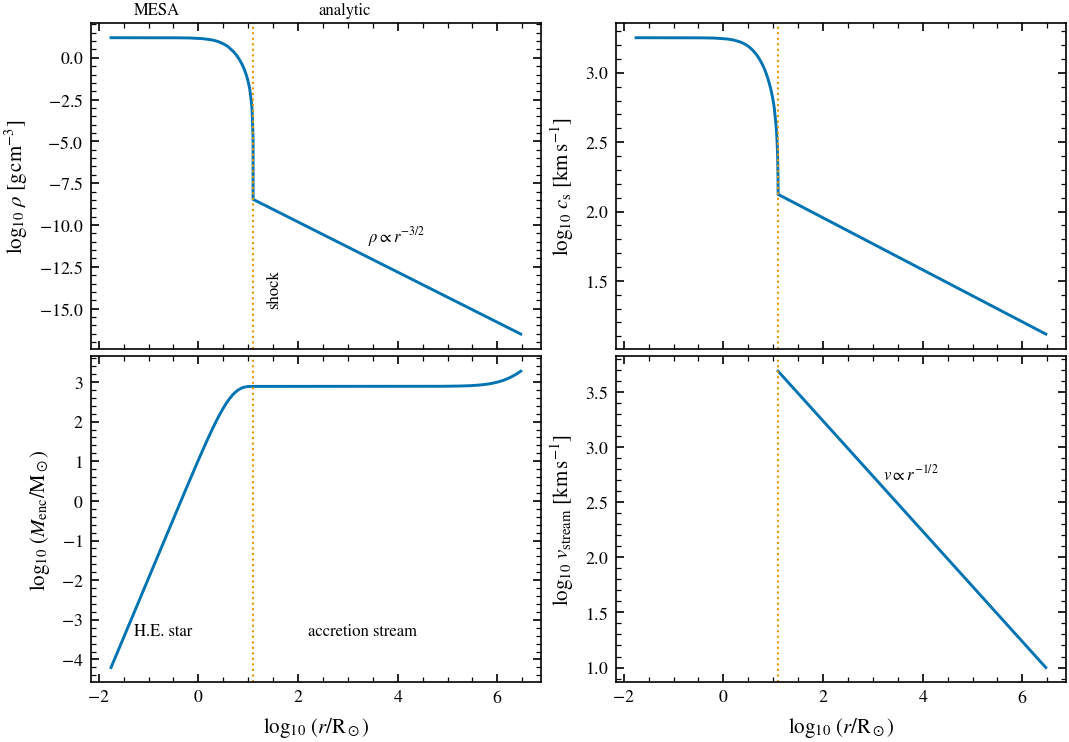


OK  stellar mass                                         code = 773       Msun      paper ~ 773      (tol x1.01)  [Sec. 2]
OK  stellar radius                                       code = 12.5      Rsun      paper ~ 12.5     (tol x1.05)  [Sec. 2]
OK  central density                                      code = 15.9      g/cm^3    paper ~ 16       (tol x1.05)  [Sec. 2]
OK  gravitational binding energy |E_grav|                code = 2.29e+53  erg       paper ~ 2.3e+53  (tol x1.1)  [Sec. 3.4]
OK  net binding energy E_* = |E_grav| - E_int            code = 2.72e+52  erg       paper ~ 2.7e+52  (tol x1.1)  [Sec. 3.3/3.6]
OK  stellar luminosity                                   code = 1.19e+41  erg/s     paper ~ 1e+41    (tol x1.5)  [Sec. 3.3]
OK  Kelvin-Helmholtz time GM^2/(RL)                      code = 4.82e+04  yr        paper ~ 5e+04    (tol x1.5)  [Sec. 3.3]
OK  Bondi accretion rate onto the star                   code = 0.063     Msun/yr   paper ~ 0.06     (tol x1.2)  [Sec. 3.3/4]

(fo

In [2]:
save(figures.fig_structure(model), "fig1_structure.pdf", "Fig. 1")
plt.show()

be = review.binding_energy_components()          # |E_grav|, E_int, and E_* = |E_grav| - E_int
E_grav, E_star = be["omega"], be["net_binding"]
L_star = mesa.photosphere_L * c.LSUN              # stellar luminosity from the MESA header
L_edd_star = physics.eddington_luminosity(model.m_star)
t_dyn = np.sqrt(model.r_shock**3 / (G * model.m_star))
t_KH = G * model.m_star**2 / (model.r_shock * L_star)        # Kelvin-Helmholtz (thermal) time
mdot_bondi = 4*np.pi * G**2 * model.m_star**2 * model.rho_agn / model.cs_agn**3

print()
check("stellar mass", model.m_star/Msun, 773, "Msun", "Sec. 2", tol=1.01)
check("stellar radius", model.r_shock/Rsun, 12.5, "Rsun", "Sec. 2", tol=1.05)
check("central density", model.rho_c, 16, "g/cm^3", "Sec. 2", tol=1.05)
check("gravitational binding energy |E_grav|", E_grav, 2.3e53, "erg", "Sec. 3.4", tol=1.1)
check("net binding energy E_* = |E_grav| - E_int", E_star, 2.7e52, "erg", "Sec. 3.3/3.6", tol=1.1)
check("stellar luminosity", L_star, 1e41, "erg/s", "Sec. 3.3", tol=1.5)
check("Kelvin-Helmholtz time GM^2/(RL)", t_KH/YR, 5e4, "yr", "Sec. 3.3", tol=1.5)
check("Bondi accretion rate onto the star", mdot_bondi*YR/Msun, 6e-2, "Msun/yr", "Sec. 3.3/4", tol=1.2)
print(f"\n(for reference: dynamical time sqrt(R^3/GM) = {t_dyn/HR:.2f} hr, "
      f"core gas fraction beta = {review.cs_at(review.sound_speed_prescriptions(), 0.5*Rsun, 'beta'):.2f})")

## 2. Does a black hole disturb the star? (paper Sec. 3.1)

Before following a BH through the star we check that it does not wreck the star on the way in.

* **Gravitational reach.** The BH captures gas within its *Bondi–Hoyle–Lyttleton radius* $r_{\rm BHL}$. For a
  BH on a circular orbit this is simply $r_{\rm BHL}/r \simeq 2M_{\rm BH}/M_{\rm en}(r)$, a few per cent for a
  10 $M_\odot$ BH, so the BH is a small perturbation until it reaches the inner $\sim R_\odot$.
* **Tidal radius of the core** $r_{\rm t,c}\simeq(M_{\rm BH}/\rho_c)^{1/3}$: inside this the BH shreds the dense
  core.
* **Slow sinking.** The BH completes a few hundred orbits while it sinks, so the star has time to readjust as it
  passes.
* **Photon trapping.** Light produced by accretion onto the BH is dragged inward with the falling gas faster
  than it can diffuse out ($t_{\rm diff}/t_{\rm acc}\gg1$ everywhere), so accretion cannot heat the star by
  radiation alone.

In [3]:
r_tc = (MBH / model.rho_c)**(1/3)
sink = inspiral.spiral_in_time(model, MBH, model.r_shock)     # used again in Sec. 3
om = np.sqrt(G * sink["m_enc"] / sink["r"]**3)                  # orbital frequency along the path
J = MBH * np.sqrt(G * sink["m_enc"] * sink["r"])                # orbital angular momentum
dt_dr = np.gradient(J, sink["r"]) * om / sink["L_total"]        # time spent per unit radius
n_orbits = np.trapezoid(om * dt_dr, sink["r"]) / (2*np.pi)

# photon trapping: diffusion time across the Bondi sphere vs infall time, along the profile
inside = (model.r < model.r_shock) & (model.m_enc > 2*MBH)
r_, rho_, men_ = model.r[inside], model.rho[inside], model.m_enc[inside]
r_bhl = 2 * G * MBH / (G * men_ / r_)
trap = (r_bhl * rho_ * r_bhl * 0.34 / c.C) / np.sqrt(r_bhl**3 / (G * MBH))

check("r_BHL / r at M_en = 500 Msun", 2*MBH/(500*Msun), 4e-2, "", "Sec. 3.1, Eq. 1", tol=1.05)
check("core tidal radius r_t,c", r_tc/Rsun, 1.5, "Rsun", "Sec. 3.1, Eq. 2", tol=1.1)
check("orbits completed while sinking", n_orbits, 100, "", "Sec. 3.1 'O(100)'", tol=5)
check("photon trapping t_diff/t_acc near the surface", trap[-1], 5e2, "", "Sec. 3.1", tol=1.5)
check("photon trapping t_diff/t_acc deep inside (>~1e8)", trap[0], 1e8, "", "Sec. 3.1 (lower bound)", tol=100)

OK  r_BHL / r at M_en = 500 Msun                         code = 0.04                paper ~ 0.04     (tol x1.05)  [Sec. 3.1, Eq. 1]
OK  core tidal radius r_t,c                              code = 1.55      Rsun      paper ~ 1.5      (tol x1.1)  [Sec. 3.1, Eq. 2]
OK  orbits completed while sinking                       code = 220                 paper ~ 100      (tol x5)  [Sec. 3.1 'O(100)']
OK  photon trapping t_diff/t_acc near the surface        code = 498                 paper ~ 500      (tol x1.5)  [Sec. 3.1]
OK  photon trapping t_diff/t_acc deep inside (>~1e8)     code = 1.62e+09            paper ~ 1e+08    (tol x100)  [Sec. 3.1 (lower bound)]


## 3. A single black hole sinks into the star (paper Sec. 3.3, Figs. 2–4)

A BH captured near the surface moves on a nearly circular orbit and loses energy to three channels:
dynamical friction, accretion drag and (negligibly, for a lone BH) gravitational waves. Because the BH orbits
the stellar mass *inside* its orbit, $M_{\rm en}(r)$, rather than a point mass, we follow the loss of orbital
angular momentum $J=m_{\rm BH}\sqrt{GM_{\rm en}r}$:

$$\frac{dJ}{dt} = -\frac{L_{\rm DF}+L_{\rm acc}+L_{\rm GW}}{\Omega(r)},\qquad \Omega=\sqrt{GM_{\rm en}/r^3}.$$

### Fig. 2 — how long the sinking takes

A 10 $M_\odot$ BH reaches the core in about 0.1 yr (roughly a month). Heavier BHs sink faster. Most of the
time is spent in the thin outer layers, where the drag is weakest; the plunge through the dense interior is quick.

Fig. 2 -> figures/fig3_caseA_inspiral.pdf


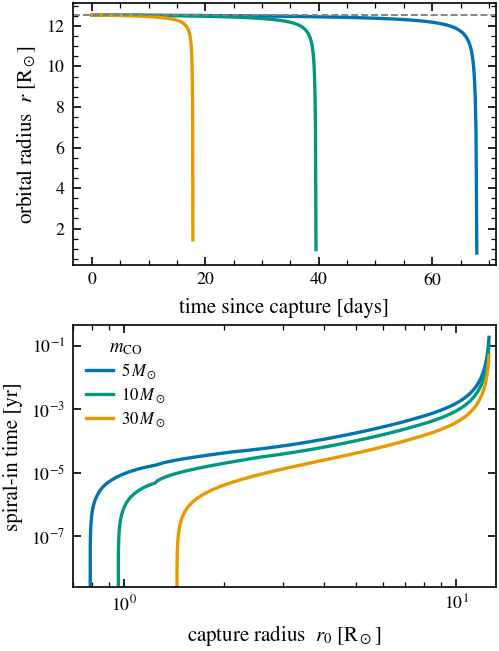

OK  sinking time, 10 Msun BH from the surface            code = 0.108     yr        paper ~ 0.1      (tol x1.5)  [Sec. 3.3]
OK  radius where enclosed star mass = BH mass            code = 0.96      Rsun      paper ~ 0.96     (tol x1.05)  [Sec. 3.3 / Fig. 3a]


In [4]:
save(figures.fig_inspiral(model, masses=(5, 10, 30)), "fig3_caseA_inspiral.pdf", "Fig. 2")
plt.show()
check("sinking time, 10 Msun BH from the surface", sink["t_total"]/YR, 0.1, "yr", "Sec. 3.3", tol=1.5)
check("radius where enclosed star mass = BH mass", sink["r_final"]/Rsun, 0.96, "Rsun", "Sec. 3.3 / Fig. 3a", tol=1.05)

### Fig. 3 — the actual paths

Both panels plot the real integrated trajectory, using the orbital phase accumulated along the way (nothing
schematic).

**(a)** A single BH sinking from the surface (linear radius). The pink core is where the enclosed stellar mass
falls below the BH mass and our "small body in a big star" treatment stops being valid.

**(b)** The same, but with a second BH already sitting at the center, followed all the way to merger (log radius).
The pair winds around about 3000 times, with the orbits bunching up where gas drag hands over to GW emission.
Inside the pink region ($r\lesssim0.5\,R_\odot$) each BH's capture radius is larger than its orbit, so only a
full 3D simulation can describe the gas there.

Fig. 3 -> figures/fig9_spiral_trajectories.pdf


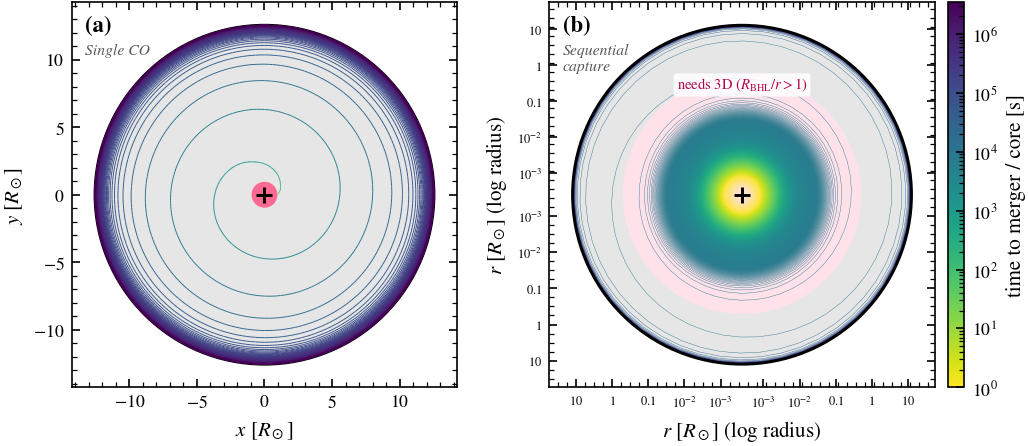

OK  windings of the second BH to merger (Fig. 3b)        code = 3.75e+03            paper ~ 3e+03    (tol x1.3)  [Sec. 3.4 / Fig. 3]
OK  3D-breakdown radius R_BHL/r = 1 (Fig. 3b)            code = 0.51      Rsun      paper ~ 0.51     (tol x1.05)  [Fig. 3 caption]


In [5]:
save(review.fig_true_trajectories(model), "fig9_spiral_trajectories.pdf", "Fig. 3")
plt.show()

# the two numbers quoted for panel (b): number of windings and the 3D-breakdown radius
rB = np.logspace(np.log10(bbh.a_isco(MBH, MBH)), np.log10(model.r_shock), 300000)
chB = inspiral.channel_luminosities(model, MBH, rB, m_central=MBH)
omB = chB["v_c"] / rB
dtB = np.gradient(MBH * np.sqrt(G * chB["m_enc"] * rB), rB) * omB / chB["L_total"]
n_wind = np.trapezoid(omB * dtB, rB) / (2*np.pi)
r_bhl_over_r = 2*G*MBH / (chB["v_c"]**2 + chB["cs"]**2) / rB
r_3d = rB[np.where(r_bhl_over_r > 1)[0][-1]]
check("windings of the second BH to merger (Fig. 3b)", n_wind, 3000, "", "Sec. 3.4 / Fig. 3", tol=1.3)
check("3D-breakdown radius R_BHL/r = 1 (Fig. 3b)", r_3d/Rsun, 0.51, "Rsun", "Fig. 3 caption", tol=1.05)

### Fig. 4 — which channel removes the energy

Power taken out of the orbit of a 10 $M_\odot$ BH circling a second 10 $M_\odot$ BH at the center (a companion is
needed for GW emission to appear at all). Dynamical friction dominates almost everywhere; GW emission only catches
up very close to the center. The lower panel shows that the orbit is supersonic (Mach > 1) inside the star.

Fig. 4 -> figures/fig2_caseA_powers.pdf


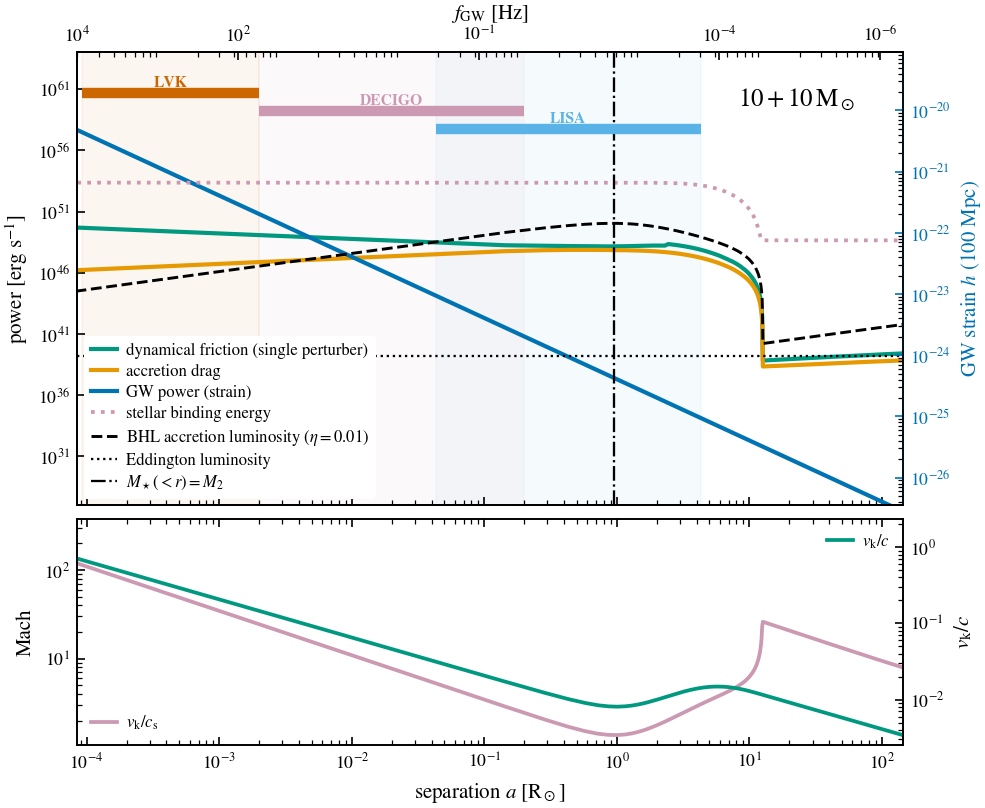

In [6]:
save(figures.fig_power(model), "fig2_caseA_powers.pdf", "Fig. 4")
plt.show()

### What happens once the BH reaches the center (paper Sec. 3.3)

The paper brackets the fate of a star with one BH at its center between two limits:

* **Unregulated.** If the BH swallows gas at the BHL rate, which is about $10^6\,M_\odot$/yr in the core and
  $\sim10^{12}$ times its Eddington rate, it consumes the core within hours and the star dies in a collapsar-like
  explosion.
* **Regulated.** If feedback limits the BH to roughly the Eddington luminosity, the star survives for a long time
  as a *quasi-star*, a star powered partly by a central BH.

Drag on the way in cannot destroy the star by itself: the energy dissipated during the sinking (at most
$m_{\rm BH}\lvert\Phi_{\rm c}\rvert$, with $\Phi_{\rm c}$ the gravitational potential at the center) is offset
by the BH settling deeper into the star's potential.

The checks below cover the numbers that set these limits, including the two conditions the star must meet to
survive until a second BH arrives (one every $\Gamma^{-1}\approx5\times10^4$ yr; paper Sec. 4).

In [7]:
# drag and accretion along the way in
rho_s, cs_s, v_s = sink["rho"], sink["cs"], sink["v_c"]
m_acc_bhl = np.trapezoid(physics.bhl_accretion_rate(rho_s, MBH, cs_s, v_s) * dt_dr, sink["r"])
c10 = inspiral.channel_luminosities(model, MBH, np.array([10*Rsun]))
L_acc10 = 0.1 * physics.bhl_accretion_rate(c10["rho"], MBH, c10["cs"], c10["v_c"])[0] * c.C**2

# gravitational potential at the center (integrate g = G M(<r)/r^2 inward from the surface)
r_in, M_in = (10**mesa.logR)[::-1]*Rsun, mesa.mass[::-1]*Msun
phi_c = -G*model.m_star/model.r_shock - np.trapezoid(G*M_in/r_in**2, r_in)

# the two limits once the BH sits in the core
cs_c = float(model.cs_of_r(model.r[1]))
mdot_core = physics.bhl_accretion_rate(model.rho_c, MBH, cs_c, 0.0)
mdot_edd_bh = physics.eddington_accretion_rate(MBH)            # eta = 0.1
L_edd_bh = physics.eddington_luminosity(MBH)
Gamma = rates.encounter_rate()                                   # BH encounters per second (Sec. 4)

check("BHL mass a 10 Msun BH would gain while sinking", m_acc_bhl/Msun, 9, "Msun", "Sec. 3.3", tol=1.2)
check("eta*Mdot_BHL*c^2 at r = 10 Rsun (eta = 0.1)", L_acc10, 1e48, "erg/s", "Sec. 3.3", tol=2)
check("max drag energy m_BH |Phi_c| (offset by settling)", MBH*abs(phi_c), 1e52, "erg", "Sec. 3.3", tol=2)
check("BHL accretion rate in the core", mdot_core*YR/Msun, 1e6, "Msun/yr", "Sec. 3.3", tol=1.5)
check("core BHL rate / BH Eddington rate", mdot_core/mdot_edd_bh, 1e12, "", "Sec. 3.3 'some 1e12'", tol=5)
check("Eddington luminosity of a 10 Msun BH", L_edd_bh, 1.5e39, "erg/s", "Sec. 3.3", tol=1.05)
check("L_Edd,BH / L_*", L_edd_bh/L_star, 0.01, "", "Sec. 3.3 '~1%'", tol=1.5)
check("time to deliver E_* at L_Edd,BH", E_star/L_edd_bh/MYR, 0.6, "Myr", "Sec. 3.3", tol=1.1)
check("BH-to-star mass ratio", MBH/model.m_star, 0.013, "", "Sec. 3.3", tol=1.05)
check("star's regrowth vs BH's Eddington growth (MESA)", mesa.star_mdot*Msun/YR/mdot_edd_bh, 1e4, "", "Sec. 3.3 '~1e4'", tol=5)
check("survival bound on mechanical power E_* Gamma", E_star*Gamma, 2e40, "erg/s", "Sec. 3.3", tol=1.3)
check("  ... as a fraction of L_Edd,*", E_star*Gamma/L_edd_star, 0.15, "", "Sec. 3.3", tol=1.1)
check("survival bound on BH growth m_BH Gamma", MBH*Gamma*YR/Msun, 2e-4, "Msun/yr", "Sec. 3.3", tol=1.05)
check("quasi-star accretion rate L_Edd,*/(0.1 c^2)", L_edd_star/(0.1*c.C**2)*YR/Msun, 2e-5, "Msun/yr", "Sec. 3.3", tol=1.1)

OK  BHL mass a 10 Msun BH would gain while sinking       code = 9.29      Msun      paper ~ 9        (tol x1.2)  [Sec. 3.3]
OK  eta*Mdot_BHL*c^2 at r = 10 Rsun (eta = 0.1)          code = 1.25e+48  erg/s     paper ~ 1e+48    (tol x2)  [Sec. 3.3]
OK  max drag energy m_BH |Phi_c| (offset by settling)    code = 8.55e+51  erg       paper ~ 1e+52    (tol x2)  [Sec. 3.3]
OK  BHL accretion rate in the core                       code = 9.74e+05  Msun/yr   paper ~ 1e+06    (tol x1.5)  [Sec. 3.3]
OK  core BHL rate / BH Eddington rate                    code = 3.76e+12            paper ~ 1e+12    (tol x5)  [Sec. 3.3 'some 1e12']
OK  Eddington luminosity of a 10 Msun BH                 code = 1.47e+39  erg/s     paper ~ 1.5e+39  (tol x1.05)  [Sec. 3.3]
OK  L_Edd,BH / L_*                                       code = 0.0123              paper ~ 0.01     (tol x1.5)  [Sec. 3.3 '~1%']
OK  time to deliver E_* at L_Edd,BH                      code = 0.586     Myr       paper ~ 0.6      (tol x1.1)  [Sec. 

## 4. A binary black hole inside the star (paper Sec. 3.4–3.5, Figs. 5–6)

Once two BHs sit in the core they form a tight binary ($a\lesssim R_\odot$), which is too tightly bound to be
broken up by passing BHs. Its own orbit then shrinks through the same gas channels as before, now competing
with GW emission.

How strongly the gas drags on a *binary* (rather than on a single BH) is uncertain. The paper therefore uses a
"ladder" of six drag prescriptions (Appendix B, Fig. 9). The fiducial one, Model 2, combines the nonlinear
drag of each BH's own wake (Kim 2010) with the partial cancellation from its companion's wake (Kim, Kim &
Sánchez-Salcedo 2008). All binary results use Model 2 at the core density and sound speed.

### Fig. 5 — gas versus GW for the binary's orbit

Gas drag (grey band = range of prescriptions; solid = fiducial) beats GW emission by many orders of magnitude
until the BHs are very close. The lower panel shows where the simple "two independent point masses" picture fails:
wherever the plotted ratios exceed 1.

Fig. 5 -> figures/fig4_caseB_powers.pdf


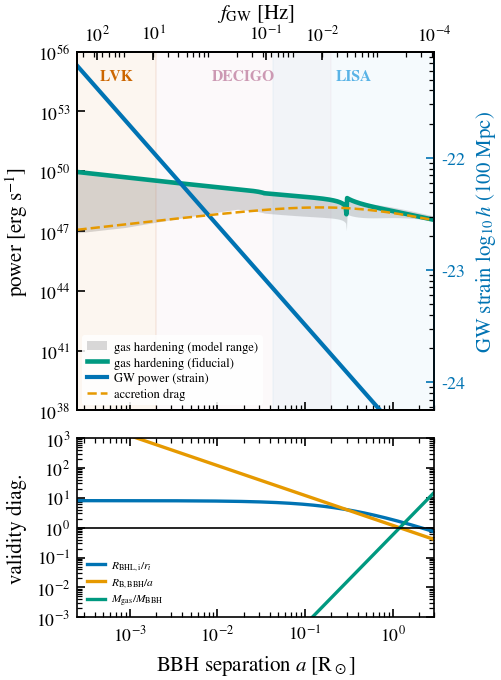

merger time from a = 1 Rsun [hr]   (gas-only c_s | radiation-inclusive c_s)
  Model 0: independent wake / upper-drag baseline          0.973 |       3.01
  Model 1: linear self + KKSS08 companion               1.74e+04 |        125
  Model 2: nonlinear self + KKSS08 (fiducial)               1.06 |        3.6
  Model 3: CE wind-tunnel $C_d$                             6.65 |       6.84
  Model 4: shared-Bondi suppressed                          7.49 |       20.2
  Model 5: scaled companion (stress test)                   1.52 |       4.33
  vacuum (GW only): 7.5e+04 yr

OK  Hill radius, 120 Msun at 1e3 r_g of a 1e8 Msun SMBH  code = 1.56e+03  Rsun      paper ~ 1.5e+03  (tol x1.1)  [Sec. 3.4]
OK  binary binding energy at a = 1 Rsun                  code = 1.9e+50   erg       paper ~ 1.9e+50  (tol x1.05)  [Sec. 3.4]
OK  binary orbital speed at a = 1 Rsun                   code = 1.95e+03  km/s      paper ~ 2e+03    (tol x1.05)  [Sec. 3.4]
OK  merger time, fiducial (Model 2)               

In [8]:
save(review.fig_power_caseB(model), "fig4_caseB_powers.pdf", "Fig. 5")
plt.show()

pres = review.sound_speed_prescriptions()
cs_gas = review.cs_at(pres, 0.5*Rsun, "cs_gas")      # fiducial core sound speed (gas pressure only)
cs_tot = review.cs_at(pres, 0.5*Rsun, "cs_tot")      # including radiation pressure (~2x larger)

def ladder(cs):
    "Merger time from a = 1 Rsun for each of the six drag prescriptions [hr]."
    return np.array([bbh.merger_time_model(MBH, MBH, Rsun, model.rho_c, cs, model=k)
                     for k in range(6)]) / HR

t_gas, t_tot = ladder(cs_gas), ladder(cs_tot)
t_vac = physics.t_merge_gw(MBH, MBH, Rsun)
print("merger time from a = 1 Rsun [hr]   (gas-only c_s | radiation-inclusive c_s)")
for k in range(6):
    print(f"  Model {k}: {bbh.HARDENING_MODELS[k]:<42s} {t_gas[k]:10.3g} | {t_tot[k]:10.3g}")
print(f"  vacuum (GW only): {t_vac/YR:.3g} yr\n")

phys = [0, 2, 3, 4, 5]          # 'physically motivated' rungs; Model 1 (pure linear) is the cautionary limit
R_hill = 1e3 * (G*1e8*Msun/c.C**2) * (120*Msun / (3e8*Msun))**(1/3)
check("Hill radius, 120 Msun at 1e3 r_g of a 1e8 Msun SMBH", R_hill/Rsun, 1500, "Rsun", "Sec. 3.4", tol=1.1)
check("binary binding energy at a = 1 Rsun", physics.orbital_energy(MBH, MBH, Rsun), 1.9e50, "erg", "Sec. 3.4", tol=1.05)
check("binary orbital speed at a = 1 Rsun", physics.v_kepler(MBH, MBH, Rsun)/1e5, 2000, "km/s", "Sec. 3.4", tol=1.05)
check("merger time, fiducial (Model 2)", t_gas[2], 1, "hr", "Sec. 3.4", tol=1.2)
check("merger time, fastest physical rung", t_gas[phys].min(), 1, "hr", "Sec. 3.4 '1-8 hr'", tol=1.2)
check("merger time, slowest physical rung", t_gas[phys].max(), 8, "hr", "Sec. 3.4 '1-8 hr'", tol=1.2)
check("merger time, pure-linear rung (near-stall)", t_gas[1]*HR/YR, 1, "yr", "Sec. 3.4 'yr-scale'", tol=3)
check("min speed-up over vacuum (all rungs)", (t_vac/HR/t_gas).min(), 1e4, "", "Sec. 3.4 '>= 1e4'", tol=10)
check("core gas fraction beta = P_gas/P_tot", review.cs_at(pres, 0.5*Rsun, "beta"), 0.2, "", "Sec. 3.4", tol=1.2)
check("radiation-inclusive c_s / gas-only c_s", cs_tot/cs_gas, 2, "", "Sec. 3.4", tol=1.1)
check("fiducial merger time, radiation-inclusive c_s", t_tot[2], 4, "hr", "Sec. 3.4", tol=1.2)
check("fastest physical rung, radiation-inclusive c_s", t_tot[phys].min(), 3, "hr", "Sec. 3.4 '3-20 hr'", tol=1.2)
check("slowest physical rung, radiation-inclusive c_s", t_tot[phys].max(), 20, "hr", "Sec. 3.4 '3-20 hr'", tol=1.2)
check("vacuum merger time from 1 Rsun (Eq. tgw)", t_vac/MYR, 0.08, "Myr", "Sec. 3.4", tol=1.1)

### Fig. 6 — energy dumped into the star

As the binary hardens, the orbital energy it loses goes into the surrounding gas. The cumulative amount,
$E_{\rm gas}(<a)\approx Gm_1m_2/2a$, reaches the star's net binding energy $E_\ast$ when the BHs are about
$7\times10^{-3}\,R_\odot$ apart, and keeps rising until GW emission takes over. Most of this happens while the
binary is radiating at deci-Hz frequencies (0.1–4 Hz). Even a modest 10+10 $M_\odot$ binary can therefore heat
its host by about its own binding energy.

Unlike a single BH sinking (Section 3 of this notebook), this is a **net** input of energy: gas far from the binary feels only its
total mass, however tight the orbit becomes, so nothing offsets the heating.

Fig. 6 -> figures/fig8_energy_deposition.pdf


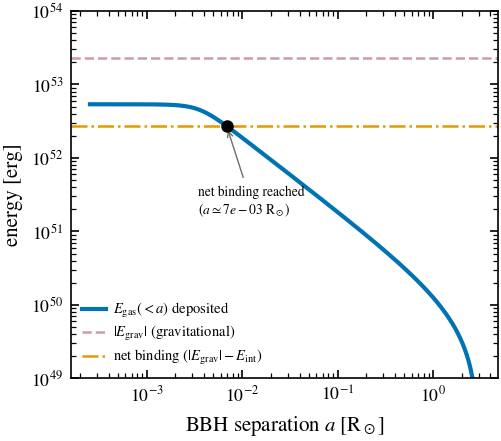

OK  separation where deposit reaches E_*                 code = 0.00689   Rsun      paper ~ 0.007    (tol x1.1)  [Sec. 3.4 / Fig. 6]
OK  deposit at a = 1e-2 Rsun                             code = 1.89e+52  erg       paper ~ 2e+52    (tol x1.2)  [Sec. 3.4]
OK    ... as a fraction of |E_grav|                      code = 0.0826              paper ~ 0.1      (tol x1.3)  [Sec. 3.4 '~10%']
OK  deposit at the deci-Hz entry (0.1 Hz) / E_*          code = 0.172               paper ~ 0.15     (tol x1.3)  [Sec. 5.1 '~15%']
OK  GW frequency at a = 0.04 Rsun                        code = 0.112     Hz        paper ~ 0.1      (tol x1.15)  [Fig. 6 caption]
OK  GW frequency at a = 0.01 Rsun                        code = 0.894     Hz        paper ~ 1        (tol x1.15)  [Fig. 6 caption]
OK  GW frequency at a = 0.004 Rsun                       code = 3.53      Hz        paper ~ 4        (tol x1.15)  [Fig. 6 caption]


In [9]:
save(review.fig_energy_deposition(model), "fig8_energy_deposition.pdf", "Fig. 6")
plt.show()

dep = review.gas_energy_deposited(MBH, MBH, 3*Rsun, model.rho_c, cs_gas)
E_at = lambda a: np.interp(np.log(a), np.log(dep["a"]), dep["E_gas"])
a_reach = dep["a"][np.argmin(np.abs(dep["E_gas"] - E_star))]
check("separation where deposit reaches E_*", a_reach/Rsun, 7e-3, "Rsun", "Sec. 3.4 / Fig. 6", tol=1.1)
check("deposit at a = 1e-2 Rsun", E_at(1e-2*Rsun), 2e52, "erg", "Sec. 3.4", tol=1.2)
check("  ... as a fraction of |E_grav|", E_at(1e-2*Rsun)/E_grav, 0.1, "", "Sec. 3.4 '~10%'", tol=1.3)
check("deposit at the deci-Hz entry (0.1 Hz) / E_*", E_at(0.04*Rsun)/E_star, 0.15, "", "Sec. 5.1 '~15%'", tol=1.3)
for a, f in ((0.04, 0.1), (0.01, 1.0), (4e-3, 4.0)):
    check(f"GW frequency at a = {a:g} Rsun", physics.gw_frequency(MBH, MBH, a*Rsun), f, "Hz", "Fig. 6 caption", tol=1.15)

### After the merger: kicks and GW energy (paper Sec. 3.4)

The merged BH gets a recoil kick. To escape, it must climb out from the *center* of the star, where the potential
is deepest. Smaller kicks are damped by the same drag within minutes, and the remnant settles back into the core.

In [10]:
omega_core = np.sqrt(4*np.pi*G*model.rho_c/3)          # oscillation frequency about the center
def stop_time(v):
    "Time for dynamical friction to stop a 20 Msun remnant kicked at speed v [hr]."
    F = physics.dynamical_friction_force(2*MBH, v, v/omega_core, cs_c, model.rho_c)
    return 2*MBH*v / F / HR

check("escape speed from the center", np.sqrt(2*abs(phi_c))/1e5, 9300, "km/s", "Sec. 3.4", tol=1.05)
check("escape speed from the surface", np.sqrt(2*G*model.m_star/model.r_shock)/1e5, 4850, "km/s", "Sec. 3.4", tol=1.05)
check("core sound speed (kick subsonic below this)", cs_c/1e5, 1800, "km/s", "Sec. 3.4", tol=1.05)
check("oscillation amplitude per 1000 km/s of kick", 1e8/omega_core/Rsun, 0.7, "Rsun", "Sec. 3.4", tol=1.1)
check("stopping time, 500 km/s kick", stop_time(500e5), 0.1, "hr", "Sec. 3.4 '0.1-0.4 hr'", tol=1.5)
check("stopping time, 5000 km/s kick", stop_time(5000e5), 0.4, "hr", "Sec. 3.4 '0.1-0.4 hr'", tol=1.5)
check("energy radiated in GWs (5% of rest mass)", 0.05*2*MBH*c.C**2, 2e54, "erg", "Sec. 3.4", tol=1.2)

OK  escape speed from the center                         code = 9.27e+03  km/s      paper ~ 9.3e+03  (tol x1.05)  [Sec. 3.4]
OK  escape speed from the surface                        code = 4.85e+03  km/s      paper ~ 4.85e+03 (tol x1.05)  [Sec. 3.4]
OK  core sound speed (kick subsonic below this)          code = 1.79e+03  km/s      paper ~ 1.8e+03  (tol x1.05)  [Sec. 3.4]
OK  oscillation amplitude per 1000 km/s of kick          code = 0.681     Rsun      paper ~ 0.7      (tol x1.1)  [Sec. 3.4]
OK  stopping time, 500 km/s kick                         code = 0.137     hr        paper ~ 0.1      (tol x1.5)  [Sec. 3.4 '0.1-0.4 hr']
OK  stopping time, 5000 km/s kick                        code = 0.283     hr        paper ~ 0.4      (tol x1.5)  [Sec. 3.4 '0.1-0.4 hr']
OK  energy radiated in GWs (5% of rest mass)             code = 1.79e+54  erg       paper ~ 2e+54    (tol x1.2)  [Sec. 3.4]


## 5. How massive can the binary be? (paper Sec. 3.6)

The energy a hardening binary dumps into the star is roughly its orbital binding energy at the **gas–GW
crossover** (inside it, GW emission carries the energy away and the stellar gas is transparent to GWs). That
energy grows as $M_{\rm BBH}^2$. Setting it equal to $E_\ast$ gives the largest equal-mass binary that can merge
without heating the star by about its binding energy. The answer, about 15 $M_\odot$, is already below the
fiducial 20 $M_\odot$, so each immortal star likely hosts only one or two mergers.

In [11]:
aa = np.logspace(np.log10(bbh.a_isco(MBH, MBH)), np.log10(Rsun), 2000)
h = bbh.hardening_rates(MBH, MBH, aa, model.rho_c, cs_gas)
a_x = aa[np.argmin(np.abs(np.log10(np.abs(h["dadt_gas"] / h["dadt_gw"]))))]   # gas rate = GW rate
E_x = physics.orbital_energy(MBH, MBH, a_x)
M_max = np.sqrt(8 * a_x * E_star / G)          # equal-mass M_BBH with G (M/2)^2 / (2 a_x) = E_*

check("gas-GW crossover separation", a_x/Rsun, 4e-3, "Rsun", "Sec. 3.6 'few x 1e-3'", tol=1.5)
check("deposit at the crossover / E_*", E_x/E_star, 2, "", "Sec. 3.6 '~2 E_*'", tol=1.2)
check("largest binary that leaves the star intact", M_max/Msun, 20, "Msun", "Sec. 3.6 '<= 20'", tol=1.5)

OK  gas-GW crossover separation                          code = 0.00382   Rsun      paper ~ 0.004    (tol x1.5)  [Sec. 3.6 'few x 1e-3']
OK  deposit at the crossover / E_*                       code = 1.83                paper ~ 2        (tol x1.2)  [Sec. 3.6 '~2 E_*']
OK  largest binary that leaves the star intact           code = 14.8      Msun      paper ~ 20       (tol x1.5)  [Sec. 3.6 '<= 20']


## 6. How often does this happen? (paper Sec. 4)

The rate estimate is a short chain of order-of-magnitude factors, all in `agn_cee.rates`:

1. **Migration time.** An immortal star drifts inward through the disk in
   $\tau_{\rm mig}\approx0.5$ Myr (fiducial disk, aspect ratio $h=10^{-3}$).
2. **Encounter rate.** Along the way it meets the $\sim10$ BHs on interior orbits:
   $\Gamma\approx10/\tau_{\rm mig}\approx20$ per Myr.
3. **Mergers per AGN.** $n_{\rm BBH}\approx20$ per AGN per Myr if every encounter merges (optimistic), or
   $1$–$2$ if, as paper Sec. 3.6 suggests, each star survives only one or two mergers.
4. **Volumetric rate.** Multiply by the number density of Milky-Way-like galaxies ($4\times10^{-3}$ Mpc$^{-3}$)
   and the fraction that host an AGN (0.1).

The result is a **ceiling**. The migration time scales as $h^2$, and the disk-averaged $h\approx0.03$ would make
migration $\sim900$ times slower, so the true rate could be much lower.

In [12]:
tau_mig = rates.migration_time()
check("migration time (fiducial)", tau_mig/MYR, 0.5, "Myr", "Sec. 4, Eq. mig", tol=1.01)
check("encounter rate Gamma", Gamma*MYR, 20, "1/Myr", "Sec. 4", tol=1.01)
check("time between encounters 1/Gamma", 1/Gamma/YR, 5e4, "yr", "Sec. 4", tol=1.01)
check("merger rate, optimistic n_BBH = 20", rates.volumetric_rate(20), 8, "/Gpc^3/yr", "Sec. 4 / abstract", tol=1.01)
check("merger rate, n_BBH = 1", rates.volumetric_rate(1), 0.4, "/Gpc^3/yr", "Sec. 4", tol=1.01)
check("merger rate, n_BBH = 2", rates.volumetric_rate(2), 0.8, "/Gpc^3/yr", "Sec. 4", tol=1.01)
check("slow-down of migration for h = 0.03 vs 1e-3", rates.migration_time(h=0.03)/tau_mig, 1e3, "", "Sec. 4 '~1e3'", tol=1.2)
check("speed-up of migration for the 773 Msun model", tau_mig/rates.migration_time(M_star=model.m_star), 7.7, "", "Sec. 2", tol=1.05)

OK  migration time (fiducial)                            code = 0.5       Myr       paper ~ 0.5      (tol x1.01)  [Sec. 4, Eq. mig]
OK  encounter rate Gamma                                 code = 20        1/Myr     paper ~ 20       (tol x1.01)  [Sec. 4]
OK  time between encounters 1/Gamma                      code = 5e+04     yr        paper ~ 5e+04    (tol x1.01)  [Sec. 4]
OK  merger rate, optimistic n_BBH = 20                   code = 8         /Gpc^3/yr paper ~ 8        (tol x1.01)  [Sec. 4 / abstract]
OK  merger rate, n_BBH = 1                               code = 0.4       /Gpc^3/yr paper ~ 0.4      (tol x1.01)  [Sec. 4]
OK  merger rate, n_BBH = 2                               code = 0.8       /Gpc^3/yr paper ~ 0.8      (tol x1.01)  [Sec. 4]
OK  slow-down of migration for h = 0.03 vs 1e-3          code = 900                 paper ~ 1e+03    (tol x1.2)  [Sec. 4 '~1e3']
OK  speed-up of migration for the 773 Msun model         code = 7.73                paper ~ 7.7      (tol x1.05) 

## 7. What a gravitational-wave detector would see (paper Sec. 5.1, Figs. 7–8)

A 10+10 $M_\odot$ binary at $a\approx R_\odot$ emits at about 1 mHz, the LISA band. In empty space it would sit
there for $\sim10^5$ yr and slowly chirp up. Inside the star, gas drag sweeps it through the LISA band in hours,
so LISA would see almost nothing. Near merger (the LVK band) gas no longer matters and the signal looks like an
ordinary merger. The environment's imprint is largest in between, at **deci-Hz** frequencies.

### Fig. 7 — dephasing

$\delta N(>f)=N_{\rm vac}-N_{\rm star}$ is how many fewer wave cycles the gas-hardened binary makes between
frequency $f$ and merger, compared with the same binary in vacuum. Filled circles mark the gas–GW crossover. In
the LISA band the huge $\delta N$ just means the binary is swept through without completing a normal inspiral.
In the LVK band only a residual of a few to ten cycles remains, after removing the parts that a shift in the
merger time and phase can absorb.

Fig. 7 -> figures/fig6_dephasing.pdf


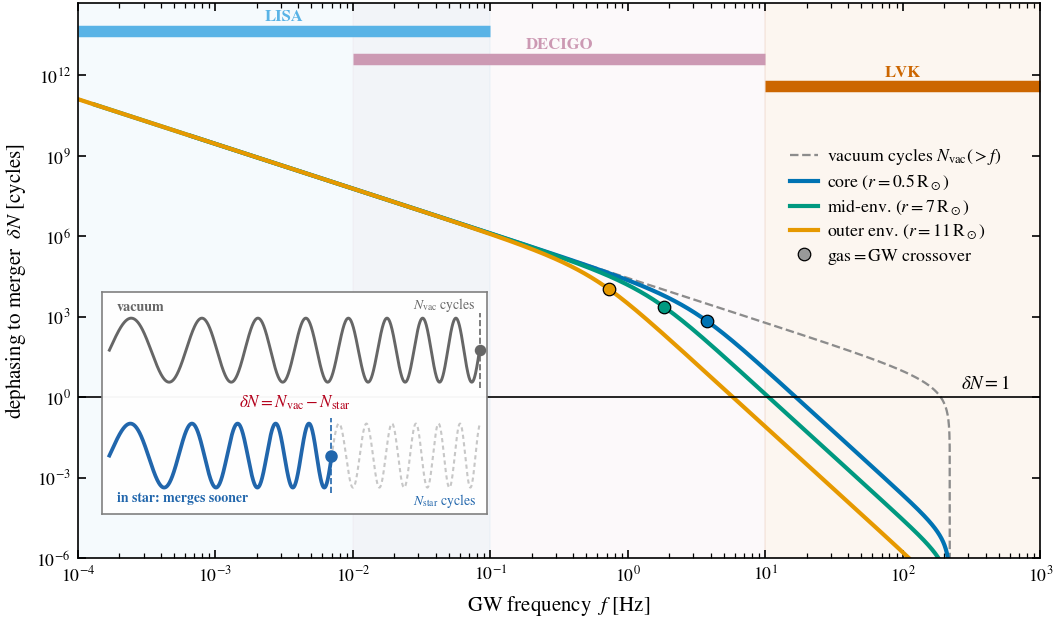

OK  GW frequency at a = 1 Rsun                           code = 0.894     mHz       paper ~ 1        (tol x1.15)  [Sec. 5.1]
OK  monochromatic LISA strain (Eq. hchar coefficient)    code = 2.68e-23            paper ~ 3e-23    (tol x1.2)  [Sec. 5.1]
OK  LVK-band residual dephasing, gas-only c_s            code = 9.51      cycles    paper ~ 10       (tol x1.5)  [Sec. 5.1 'of order ten']
OK  LVK-band residual dephasing, radiation-incl. c_s     code = 2.75      cycles    paper ~ 3        (tol x1.5)  [Sec. 5.1 'a few']


In [13]:
save(figures.fig_dephasing(model), "fig6_dephasing.pdf", "Fig. 7")
plt.show()

f_1Rsun = physics.gw_frequency(MBH, MBH, Rsun)
# Eq. hchar: monochromatic strain over 1 yr, evaluated at the paper's normalization
# (M_BBH = 20 Msun, f = 1 mHz, v_BBH = 2000 km/s, D = 100 Mpc)
h_char_mono = (G*2*MBH/c.C**2) * (2000e5/c.C)**2 / (100*c.MPC) * np.sqrt(1e-3*YR/8)
lvk_resid_gas = review.measurable_dephasing(MBH, MBH, 5*Rsun, model.rho_c, cs_gas, band=(10.0, 1e3))["resid_max"]
lvk_resid_tot = review.measurable_dephasing(MBH, MBH, 5*Rsun, model.rho_c, cs_tot, band=(10.0, 1e3))["resid_max"]

check("GW frequency at a = 1 Rsun", f_1Rsun*1e3, 1, "mHz", "Sec. 5.1", tol=1.15)
check("monochromatic LISA strain (Eq. hchar coefficient)", h_char_mono, 3e-23, "", "Sec. 5.1", tol=1.2)
check("LVK-band residual dephasing, gas-only c_s", lvk_resid_gas, 10, "cycles", "Sec. 5.1 'of order ten'", tol=1.5)
check("LVK-band residual dephasing, radiation-incl. c_s", lvk_resid_tot, 3, "cycles", "Sec. 5.1 'a few'", tol=1.5)

### Fig. 8 — signal strength against detector noise

Characteristic strain of the gas-hardened binary at 100 Mpc (solid; band = drag prescriptions) and of the same
binary in vacuum (dashed), against the LISA, DECIGO and LVK sensitivity curves. In the LISA band the gas-hardened
signal is several orders of magnitude below the vacuum one. At deci-Hz it recovers toward vacuum, and it ends as a
standard LVK merger. The signal-to-noise ratios below put numbers on this: the LVK sees an ordinary loud merger,
while DECIGO would see a signal about ten times weaker than in vacuum but still very loud.

Fig. 8 -> figures/fig7_characteristic_strain.pdf


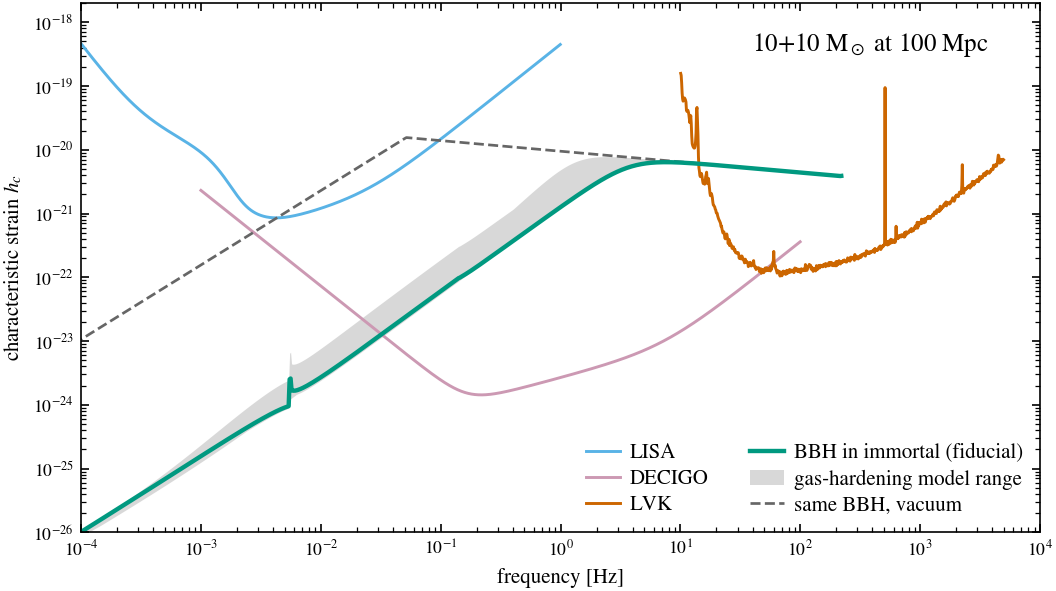

  LISA   SNR at 100 Mpc: in the star =   0.00781   in vacuum =      32.8
  DECIGO SNR at 100 Mpc: in the star =  1.22e+03   in vacuum =  1.12e+04
  LVK    SNR at 100 Mpc: in the star =      46.9   in vacuum =      46.9

OK  LVK SNR at 100 Mpc (sky-averaged)                    code = 46.9                paper ~ 50       (tol x1.2)  [Sec. 5.1]
OK  DECIGO SNR at 100 Mpc, in the star                   code = 1.22e+03            paper ~ 1.2e+03  (tol x1.1)  [Sec. 5.1]
OK  DECIGO SNR at 100 Mpc, in vacuum                     code = 1.12e+04            paper ~ 1.1e+04  (tol x1.1)  [Sec. 5.1]


In [14]:
save(review.fig_characteristic_strain(model), "fig7_characteristic_strain.pdf", "Fig. 8")
plt.show()

snr = {(d, g): observability.snr(MBH, MBH, model.rho_c, cs_gas, 100*c.MPC, d, gas=g)
       for d in ("LISA", "DECIGO", "LVK") for g in (True, False)}
for d in ("LISA", "DECIGO", "LVK"):
    print(f"  {d:<6s} SNR at 100 Mpc: in the star = {snr[(d, True)]:9.3g}   in vacuum = {snr[(d, False)]:9.3g}")
print()
check("LVK SNR at 100 Mpc (sky-averaged)", snr[("LVK", True)], 50, "", "Sec. 5.1", tol=1.2)
check("DECIGO SNR at 100 Mpc, in the star", snr[("DECIGO", True)], 1.2e3, "", "Sec. 5.1", tol=1.1)
check("DECIGO SNR at 100 Mpc, in vacuum", snr[("DECIGO", False)], 1.1e4, "", "Sec. 5.1", tol=1.1)

## 8. Appendix B — the ladder of drag prescriptions (Fig. 9)

How much faster gas hardens the binary than GW emission alone, $\lvert\dot a_{\rm gas}\rvert/\lvert\dot a_{\rm GW}\rvert$,
for the six prescriptions. Values above 1 mean gas wins. All the physically motivated prescriptions keep gas in
control until close to merger. Only the purely linear one (Model 1), which the paper treats as a cautionary
lower limit on the drag, approaches the line where gas and GW are equal.

| Model | Prescription |
|---|---|
| 0 | each BH's own wake only (independent perturbers); an upper bound on the drag |
| 1 | linear own-wake drag + companion wake; near-stalling lower limit |
| 2 | **nonlinear own-wake drag + companion wake (fiducial)** |
| 3 | drag coefficients measured in common-envelope "wind-tunnel" simulations |
| 4 | Model 2, reduced where the two BHs share one Bondi sphere |
| 5 | Model 2 with a scaled companion-wake cancellation (stress test) |

Fig. 9 (App. B) -> figures/fig5_hardening_ladder.pdf


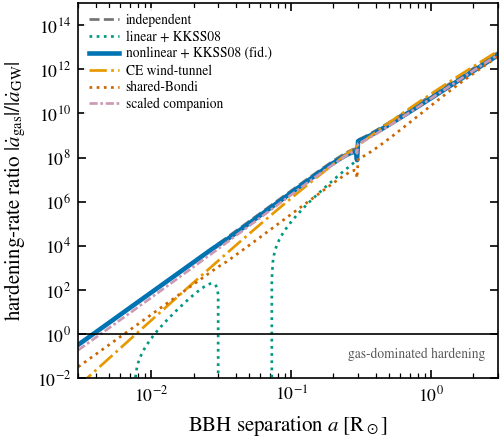

In [15]:
save(review.fig_hardening_ladder(model), "fig5_hardening_ladder.pdf", "Fig. 9 (App. B)")
plt.show()

## 9. Summary of all checks

Every number checked above, in paper order. `ratio` is code/paper; a check passes when the ratio lies within the
stated tolerance factor.

Two results in the paper are not recomputed here:

* the comparison with the stratified-wake drag of Gagnier (2026), which needs that author's external code
  (see `scripts/gagnier_stratified_check.py` and the README), and
* the statements that come from the literature rather than from our model (for example the quasi-star
  mass-ratio limits and the LVK O3 merger rate).

In [16]:
n_ok = sum(ch["ok"] for ch in CHECKS)
print(f"{'':2s}  {'quantity':<52s} {'code':>10s} {'paper':>10s} {'ratio':>7s}  tol   where")
print("-" * 112)
for ch in CHECKS:
    print(f"{'OK' if ch['ok'] else 'XX'}  {ch['what']:<52s} {ch['value']:>10.3g} {ch['paper']:>10.3g} "
          f"{ch['value']/ch['paper']:>7.2f}  x{ch['tol']:<4g} {ch['where']}")
print("-" * 112)
print(f"{n_ok} of {len(CHECKS)} checks agree with the paper.")
assert n_ok == len(CHECKS), "some numbers disagree with the paper -- see the XX lines above"

    quantity                                                   code      paper   ratio  tol   where
----------------------------------------------------------------------------------------------------------------
OK  stellar mass                                                773        773    1.00  x1.01 Sec. 2
OK  stellar radius                                             12.5       12.5    1.00  x1.05 Sec. 2
OK  central density                                            15.9         16    1.00  x1.05 Sec. 2
OK  gravitational binding energy |E_grav|                  2.29e+53    2.3e+53    0.99  x1.1  Sec. 3.4
OK  net binding energy E_* = |E_grav| - E_int              2.72e+52    2.7e+52    1.01  x1.1  Sec. 3.3/3.6
OK  stellar luminosity                                     1.19e+41      1e+41    1.19  x1.5  Sec. 3.3
OK  Kelvin-Helmholtz time GM^2/(RL)                        4.82e+04      5e+04    0.96  x1.5  Sec. 3.3
OK  Bondi accretion rate onto the star                        0.063 